In [18]:
import sys
import os
from pathlib import Path
import rasterio
import matplotlib.pyplot as plt
import numpy as np
import napari

In [40]:
project_root = Path.cwd().parent.parent
datapath = project_root / 'modis_himalaya' / 'data' / 'himalaya'

min_Mb = 250

files = [
    f for f in os.listdir(datapath)
    if os.path.getsize(os.path.join(datapath, f)) > min_Mb * 1024 * 1024
]

In [44]:
min_size = 250 #MB

# collect (file, size) pairs
files_with_size = [
    (f, f.stat().st_size)
    for f in datapath.iterdir()
    if f.is_file()
    and f.suffix.lower() == ".tif"
    and f.stat().st_size > min_size * 1024 * 1024
]

# sort by size (largest first)
files_with_size.sort(key=lambda x: x[1], reverse=True)

# split into separate lists
files = [f.name for f, _ in files_with_size]
sizes = [round(s/(1024 * 1024),2) for _, s in files_with_size]

print(files)
print(sizes)

['brighttemp_1KM_grid_modis_20170113_0555.tif', 'brighttemp_1KM_grid_modis_20170108_0535.tif', 'brighttemp_1KM_grid_modis_20170104_0600.tif', 'brighttemp_1KM_grid_modis_20170101_0530.tif', 'brighttemp_1KM_grid_modis_20170111_0605.tif', 'brighttemp_1KM_grid_modis_20170106_0545.tif']
[291.78, 282.91, 280.89, 268.74, 264.5, 262.38]


In [45]:
with rasterio.open(datapath / files[0]) as src:
    img = src.read()  # shape: (bands, height, width)
    print(img.shape)

(16, 2000, 3000)


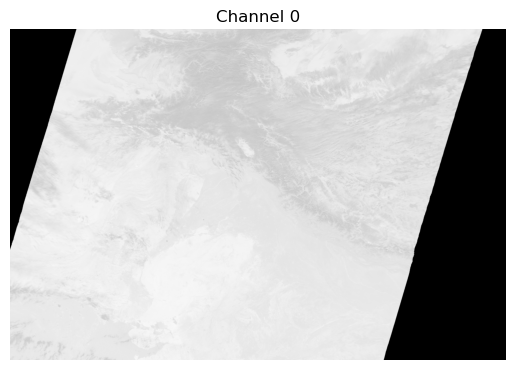

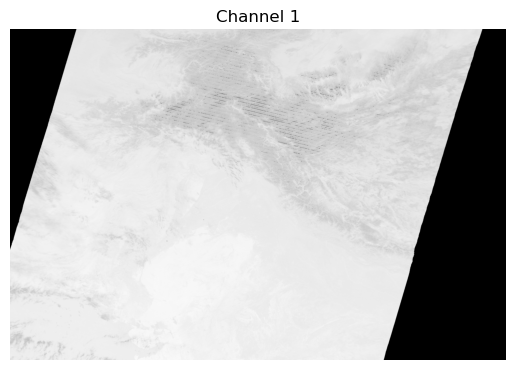

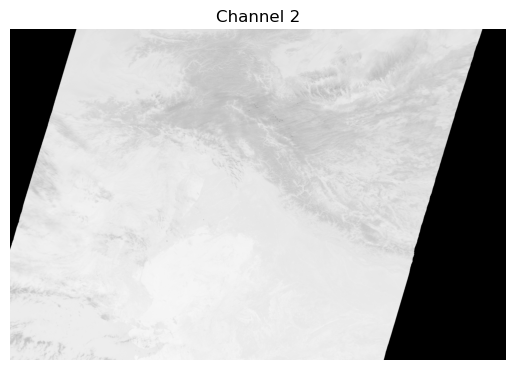

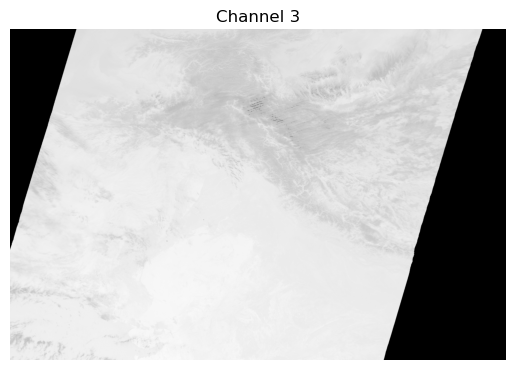

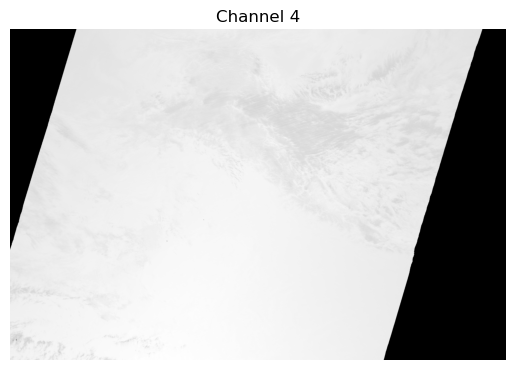

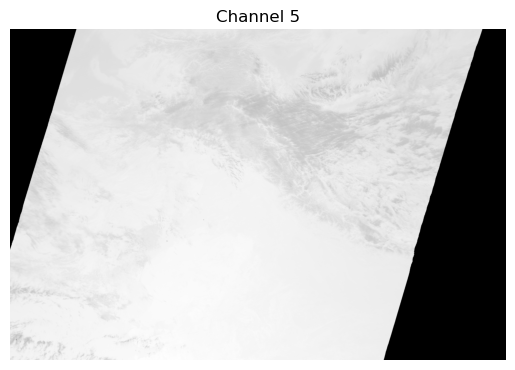

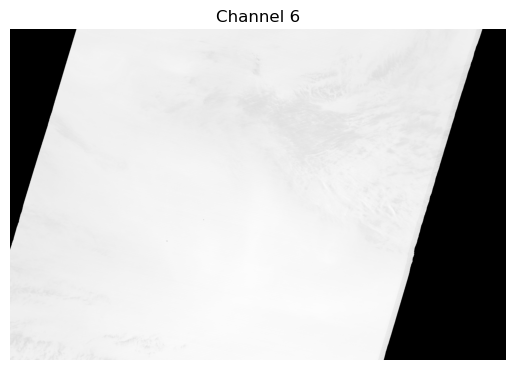

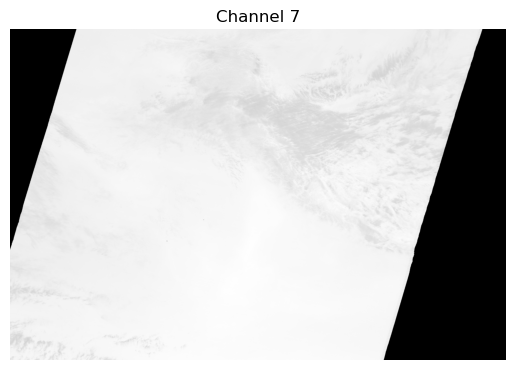

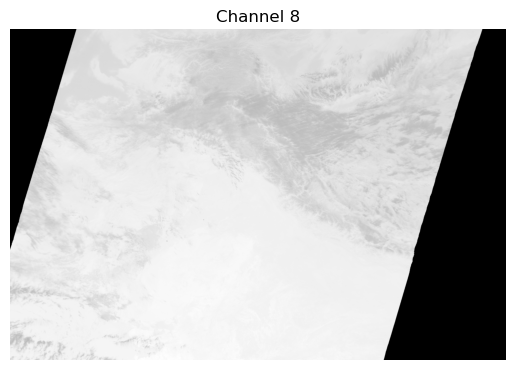

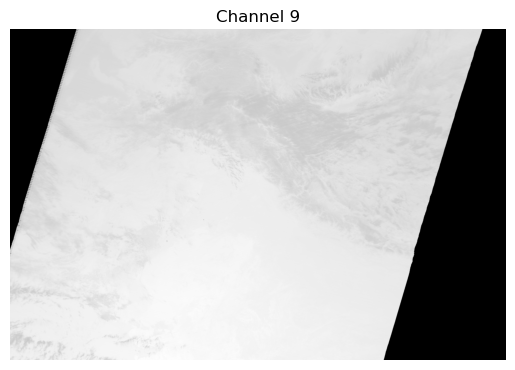

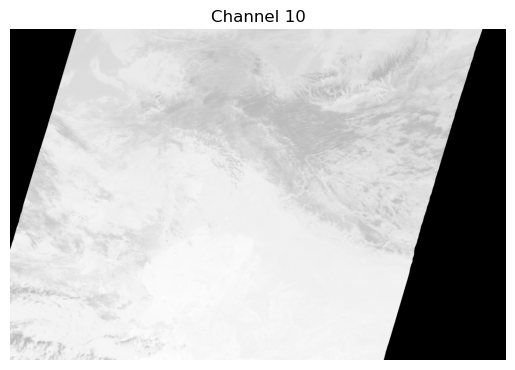

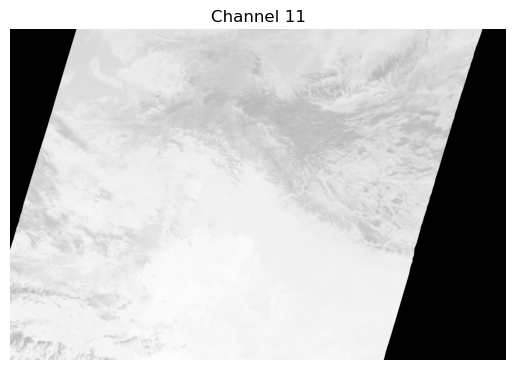

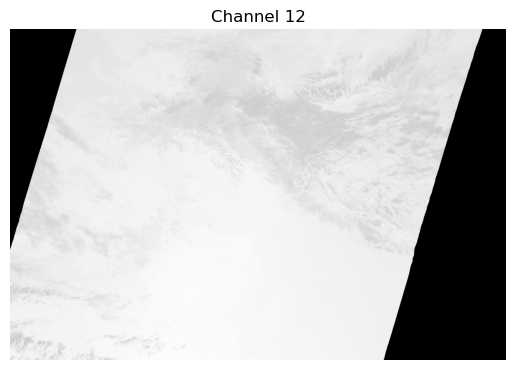

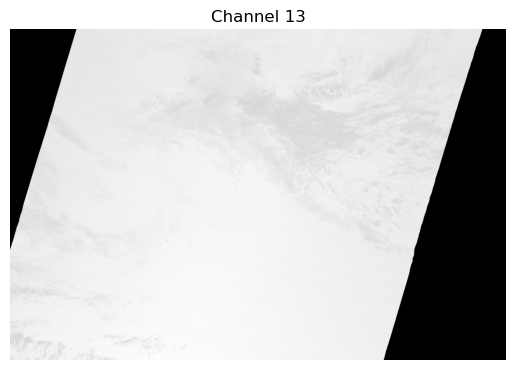

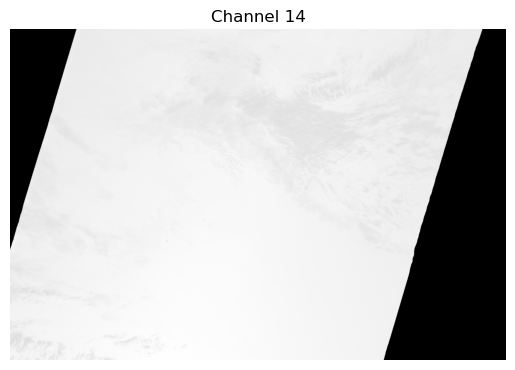

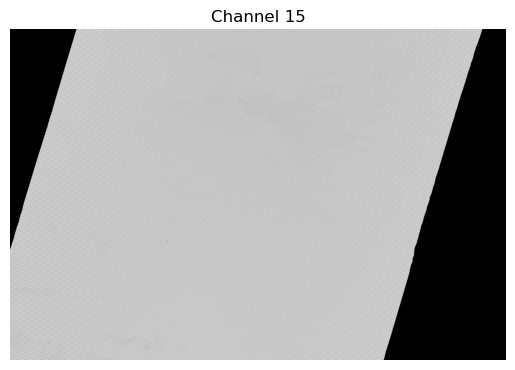

In [46]:

n_channels = img.shape[0]

for i in range(n_channels):
    plt.figure()
    plt.imshow(img[i], cmap="gray")
    plt.title(f"Channel {i}")
    plt.axis("off")

plt.show()

(16, 2000, 3000)
19641670000.0


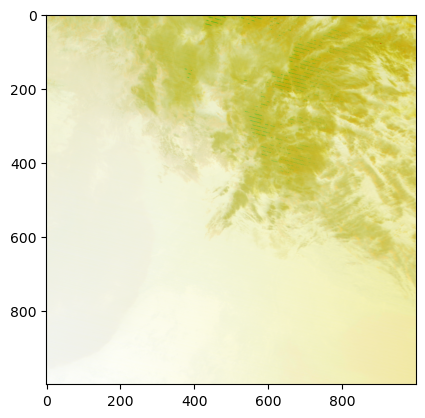

In [ ]:

def normalize(x):
    x = np.nan_to_num(x)  # remove NaNs
    x_min = np.min(x)
    x_max = np.max(x)
    
    if x_max == x_min:
        return np.zeros_like(x)
    
    return (x - x_min) / (x_max - x_min)

plt_img = img[:,500:1500,1000:2000]

r = normalize(plt_img[3])
g = normalize(plt_img[5])
b = normalize(plt_img[14])

rgb = np.stack([r, g, b], axis=-1)
print(img.shape)
print(np.sum(img))
plt.imshow(rgb)

In [20]:
viewer = napari.Viewer()

for i in range(img.shape[0]):
    viewer.add_image(
        img[i],
        name=f"band_{i}",
        colormap="gray",
        visible=(i == 0)  # only show first band initially
    )

napari.run()

In [21]:
from skimage.exposure import rescale_intensity

def safe_normalize(x):
    x = np.nan_to_num(x)

    # avoid division by zero
    vmin, vmax = np.min(x), np.max(x)
    if vmax == vmin:
        return np.zeros_like(x, dtype=np.float32)

    return (x - vmin) / (vmax - vmin)

viewer = napari.Viewer()

n_bands = img.shape[0]

for i in range(n_bands):
    band = img[i].astype(np.float32)

    # optional: remove extreme outliers (common in satellite data)
    band = np.clip(band, np.percentile(band, 2), np.percentile(band, 98))

    # normalize safely
    band = safe_normalize(band)

    viewer.add_image(
        band,
        name=f"band_{i}",
        colormap="gray",
        contrast_limits=(0, 1),
        blending="additive",
        visible=(i == 0)
    )

napari.run()